In [22]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries imported successfully")


Libraries imported successfully


In [23]:

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

df = pd.read_csv(
    url,
    names=columns,
    na_values="?"
)

print("Dataset shape:", df.shape)

display(df.head())


Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [24]:

print("Dataset Information:")
df.info()

print("\nStatistical Analysis:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["num"].value_counts(dropna=False))


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Statistical Analysis:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000



Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Target Distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [25]:

print("Missing values before treatment:")
print(df.isnull().sum())

imputer = SimpleImputer(strategy="median")

df[df.columns] = imputer.fit_transform(df)

print("\nMissing values after treatment:")
print(df.isnull().sum())


Missing values before treatment:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Missing values after treatment:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64


In [26]:

duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)


Duplicate records: 0
Dataset shape after removing duplicates: (303, 14)


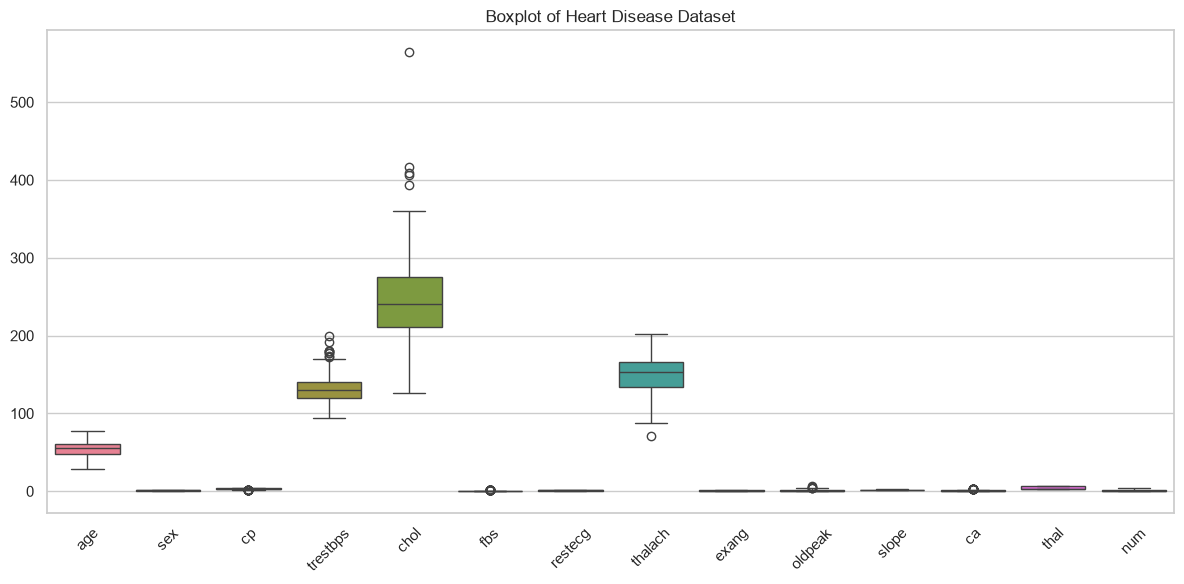

In [27]:

plt.figure(figsize=(12, 6))

sns.boxplot(data=df)

plt.title("Boxplot of Heart Disease Dataset")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [28]:

numeric_columns = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[column] = df[column].clip(lower, upper)

print("Outlier capping completed")


Outlier capping completed


In [29]:

df["target"] = (df["num"] > 0).astype(int)

df = df.drop(columns=["num"])

print(df["target"].value_counts())

print("\nTarget encoding completed")


target
0    164
1    139
Name: count, dtype: int64

Target encoding completed


In [30]:

X = df.drop(columns=["target"])

y = df["target"]

print("Independent variables:", X.shape)

print("Dependent variable:", y.shape)


Independent variables: (303, 13)
Dependent variable: (303,)


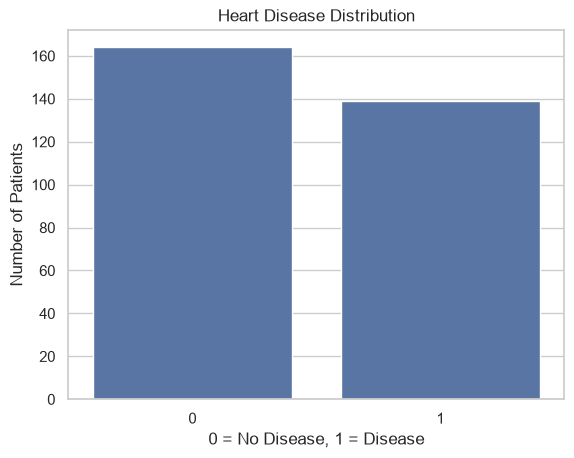

In [31]:

sns.countplot(data=df, x="target")

plt.title("Heart Disease Distribution")
plt.xlabel("0 = No Disease, 1 = Disease")
plt.ylabel("Number of Patients")

plt.show()


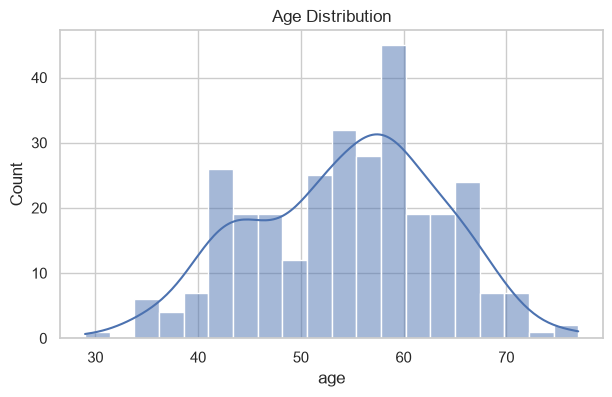

In [32]:

plt.figure(figsize=(7, 4))

sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Age Distribution")

plt.show()


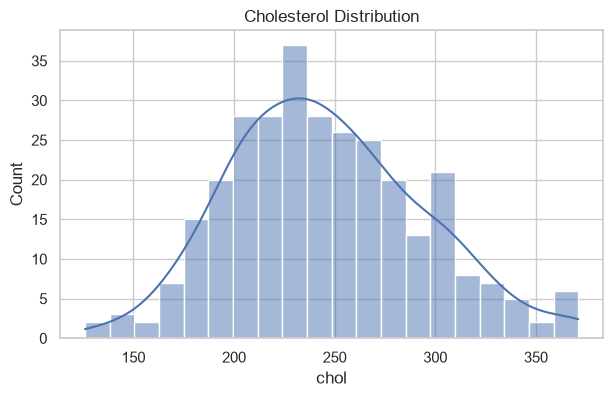

In [33]:

plt.figure(figsize=(7, 4))

sns.histplot(data=df, x="chol", bins=20, kde=True)

plt.title("Cholesterol Distribution")

plt.show()


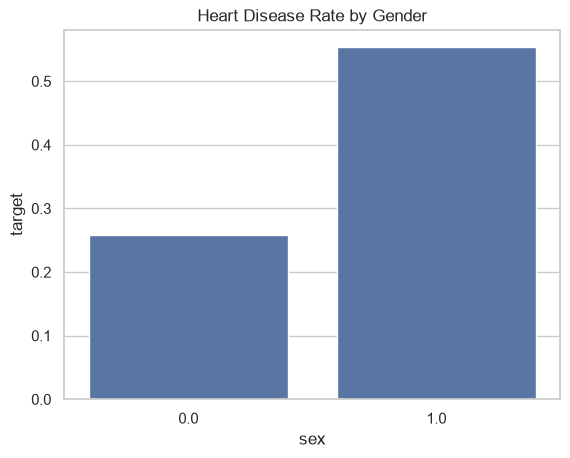

In [34]:

sns.barplot(data=df, x="sex", y="target", errorbar=None)

plt.title("Heart Disease Rate by Gender")

plt.show()


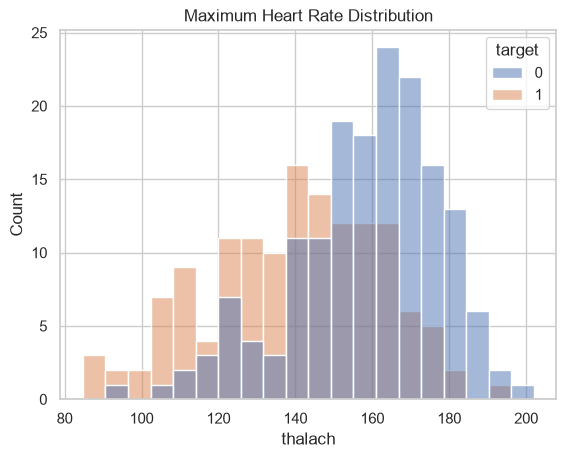

In [35]:

sns.histplot(data=df, x="thalach", hue="target", bins=20)

plt.title("Maximum Heart Rate Distribution")

plt.show()


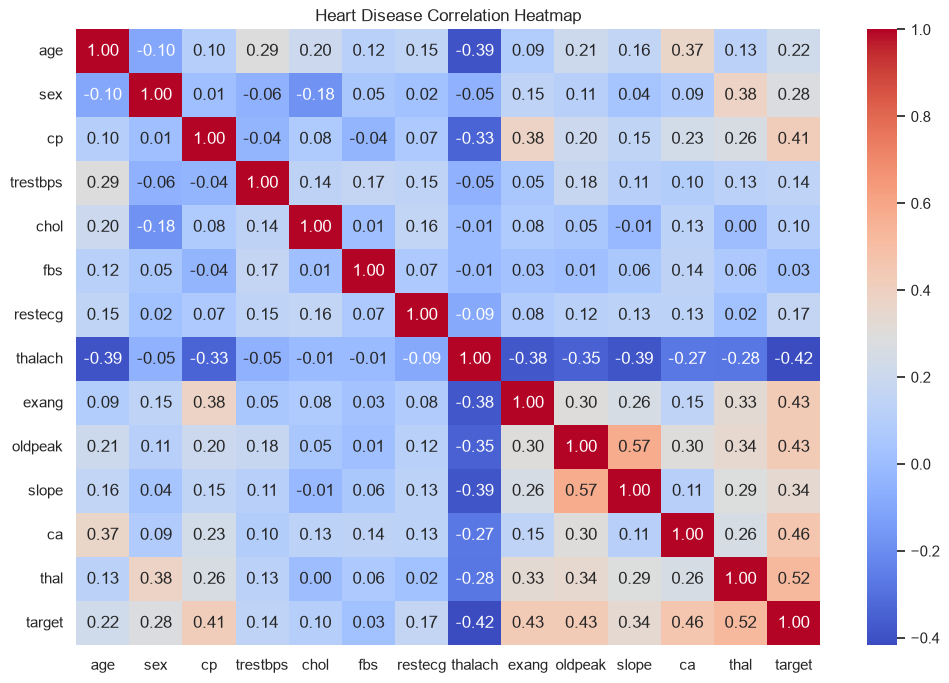

In [36]:

plt.figure(figsize=(12, 8))

sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Heart Disease Correlation Heatmap")

plt.show()


In [37]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)


Training data: (242, 13)
Testing data: (61, 13)


In [38]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Standardization completed")


Standardization completed


In [39]:

selector = SelectKBest(score_func=f_classif, k=10)

X_train_selected = selector.fit_transform(
    X_train_scaled, y_train
)

X_test_selected = selector.transform(X_test_scaled)

selected_features = X.columns[selector.get_support()]

print("Selected Features:")
print(selected_features.tolist())


Selected Features:
['age', 'sex', 'cp', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [40]:

models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

scores = []

for name, model in models.items():

    model.fit(X_train_selected, y_train)

    y_pred = model.predict(X_test_selected)

    scores.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 2),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 2),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 2),
        "F1 Score": round(f1_score(y_test, y_pred, zero_division=0), 2)
    })

results_df = pd.DataFrame(scores)

print(results_df)


                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression      0.85       0.81    0.89      0.85
1        Decision Tree      0.72       0.66    0.82      0.73
2        Random Forest      0.84       0.76    0.93      0.84
3                  KNN      0.89       0.82    0.96      0.89


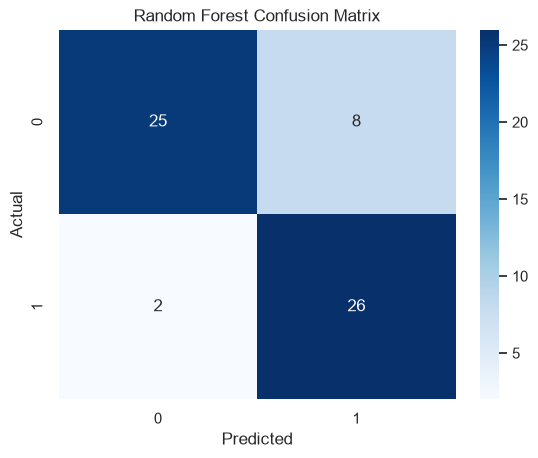

In [41]:

best_model = models["Random Forest"]

y_pred = best_model.predict(X_test_selected)

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()


In [42]:

print("HEART DISEASE PREDICTION PROJECT")

print("\nModel Performance Comparison:")
display(results_df)

best_index = results_df["F1 Score"].idxmax()

print("\nBest Model:")
print(results_df.loc[best_index, "Model"])

HEART DISEASE PREDICTION PROJECT

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.85,0.81,0.89,0.85
1,Decision Tree,0.72,0.66,0.82,0.73
2,Random Forest,0.84,0.76,0.93,0.84
3,KNN,0.89,0.82,0.96,0.89



Best Model:
KNN
